In [ ]:
import pandas as pd
import numpy as np
import os

# 1. 設定檔案路徑
trade_log_path = r"C:\Users\Lynn610\Documents\kitsune_stock_system\reports\backtest_tradelogs\trade_log_v12_rank_1_2_3_4_5.csv"
market_db_path = r"C:\Users\Lynn610\Desktop\python\量化交易_機器學習2\data\data_cleaning\market_database.csv"

print("載入資料庫中 (這可能需要幾秒鐘)...")
trade_df = pd.read_csv(trade_log_path)
market_df = pd.read_csv(market_db_path)

# 🎯 終極防呆：把所有的欄位名稱強制轉成小寫，並且去掉頭尾多餘的空白
trade_df.columns = trade_df.columns.str.lower().str.strip()
market_df.columns = market_df.columns.str.lower().str.strip()

# ==========================================
# 🌟 最低程度修改：加入「欄位轉接頭」與「量級對齊」
# ==========================================
trade_df = trade_df.rename(columns={
    '換股日期': 'date',
    '股票代碼': 'id',
    '該股當月報酬%': 'return_20d',
    '排名': 'rank'
})
# 將 23.21 轉換成 0.2321，配合停損的 0.15 以及最後結算的 * 100
trade_df['return_20d'] = trade_df['return_20d'] / 100 
# ==========================================

# 確保日期格式一致，並把 id 轉成字串防呆
trade_df['date'] = pd.to_datetime(trade_df['date'])
market_df['date'] = pd.to_datetime(market_df['date'])
trade_df['id'] = trade_df['id'].astype(str).str.replace('.0', '', regex=False) # 防呆：避免代碼變浮點數
market_df['id'] = market_df['id'].astype(str)

# 為了極速查詢，我們把本地資料庫加上 MultiIndex (股票代號, 日期)
print("建立極速查詢索引...")
market_df = market_df.sort_values(['id', 'date']).set_index(['id', 'date'])

# 2. 準備一個新的欄位來放「停損後的真實報酬」
trade_df['return_20d_SL15'] = trade_df['return_20d'] # 先預設等於原本報酬


stop_loss_threshold = 0.15
# 3. 駭客級極速迴圈：比對每一筆交易的路徑
print(f"開始進行 {stop_loss_threshold*100}% 實盤停損路徑模擬...")

# ===== 以下維持你原本的迴圈程式碼，完全不用動！ =====
for idx, row in trade_df.iterrows():
    stock_id = row['id']
    entry_date = row['date']
    
    try:
        # 抓出這檔股票在買進日之後的所有資料
        future_data = market_df.loc[stock_id].loc[entry_date:]
        
        # 我們只看買進後的「未來 20 個交易日」
        if len(future_data) > 0:
            future_20d = future_data.head(20)
            
            # 第一天的收盤價當作進場成本
            entry_price = future_20d.iloc[0]['close']
            
            # 計算這 20 天內每一天的最低價，相當於進場價的跌幅
            # formula: (Low / Entry Price) - 1
            lowest_returns = (future_20d['low'] / entry_price) - 1
            
            # 判斷這 20 天內，是否有任何一天的最低點跌破 -15%
            if (lowest_returns <= -stop_loss_threshold).any():
                # 觸發停損！無情地把這筆交易的最終報酬改寫為 -15%
                trade_df.at[idx, 'return_20d_SL15'] = -stop_loss_threshold
                
    except KeyError:
        # 如果資料庫剛好缺漏這檔股票的這段日期，就跳過不管它
        pass

print("模擬完成！")

for i in range(1,6):
	# 4. 驗證你的偉大猜想：比較有無停損的 Rank 1 期望值
	rank1_original = trade_df[trade_df['rank'] == i]['return_20d'].mean() * 100
	rank1_with_sl = trade_df[trade_df['rank'] == i]['return_20d_SL15'].mean() * 100

	print("-" * 30)
	print(f"【Rank {i} 績效對決】")
	print(f"V9 原始期望值 (死抱 20 天): {rank1_original:.2f}%")
	print(f"V9 加上實盤停損 ({stop_loss_threshold*100}%% 砍倉): {rank1_with_sl:.2f}%")
	print("-" * 30)

# 將新的日誌存檔
# trade_df.to_csv("trade_log_v9_SL15.csv", index=False)

載入資料庫中 (這可能需要幾秒鐘)...
建立極速查詢索引...
開始進行 15.0% 實盤停損路徑模擬...
模擬完成！
------------------------------
【Rank 1 績效對決】
V9 原始期望值 (死抱 20 天): 9.30%
V9 加上實盤停損 (15.0%% 砍倉): 9.22%
------------------------------
------------------------------
【Rank 2 績效對決】
V9 原始期望值 (死抱 20 天): 9.01%
V9 加上實盤停損 (15.0%% 砍倉): 9.21%
------------------------------
------------------------------
【Rank 3 績效對決】
V9 原始期望值 (死抱 20 天): 11.11%
V9 加上實盤停損 (15.0%% 砍倉): 11.40%
------------------------------
------------------------------
【Rank 4 績效對決】
V9 原始期望值 (死抱 20 天): nan%
V9 加上實盤停損 (15.0%% 砍倉): nan%
------------------------------
------------------------------
【Rank 5 績效對決】
V9 原始期望值 (死抱 20 天): nan%
V9 加上實盤停損 (15.0%% 砍倉): nan%
------------------------------


📥 正在下載 Taiwan TAIEX (大盤) (^TWII) 過去 3 年資料...


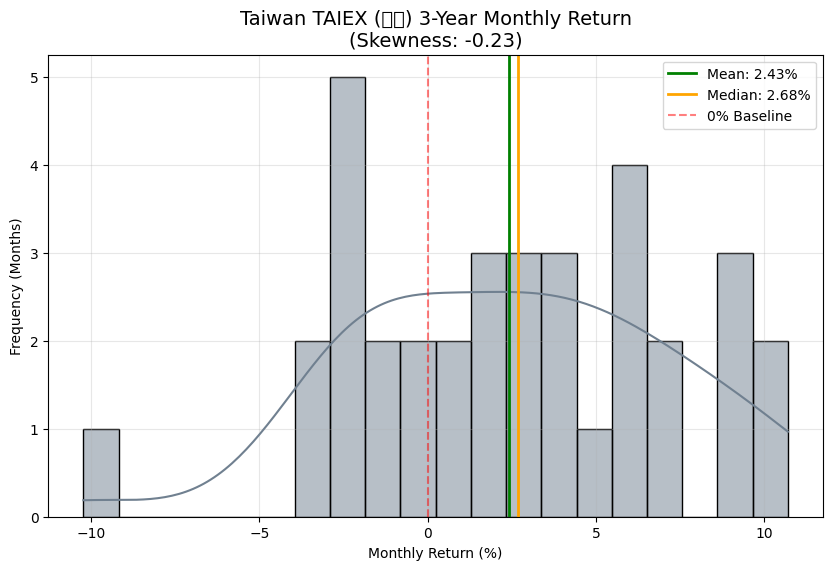

✅ Taiwan TAIEX (大盤) 過去 3 年偏態係數: -0.23
   平均數 (Mean): 2.43%
   中位數 (Median): 2.68%

📥 正在下載 Taiwan TAIEX (大盤) (^TWII) 過去 10 年資料...


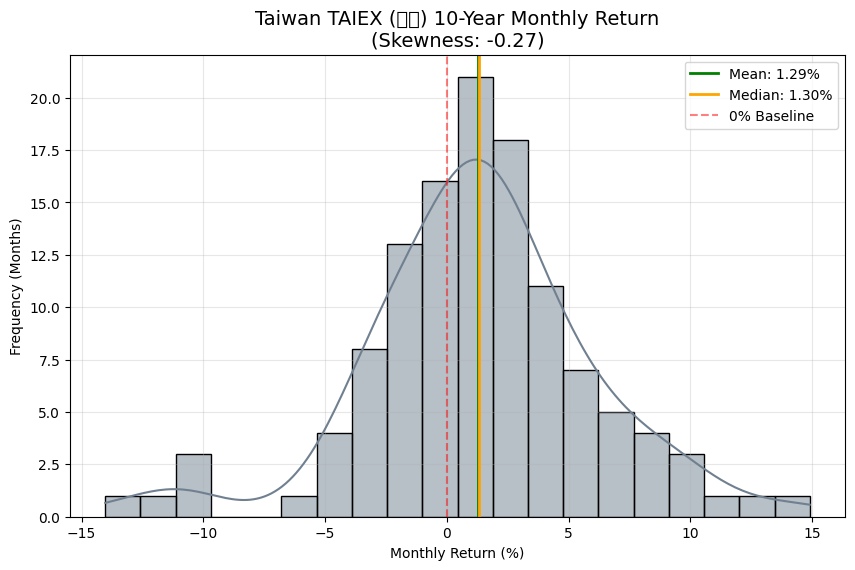

✅ Taiwan TAIEX (大盤) 過去 10 年偏態係數: -0.27
   平均數 (Mean): 1.29%
   中位數 (Median): 1.30%



In [3]:
# 大盤偏態 (新增平均數、中位數標示)
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore') # 忽略一些 yfinance 的警告

def analyze_market_skewness(ticker, name, years=3):
    print(f"📥 正在下載 {name} ({ticker}) 過去 {years} 年資料...")
    
    # 1. 設定時間範圍
    end_date = datetime.now()
    start_date = end_date - timedelta(days=years*365)
    
    # 2. 下載資料
    df = yf.download(ticker, start=start_date, end=end_date, progress=False)
    
    # 處理 yfinance 可能回傳 MultiIndex 的情況
    if isinstance(df.columns, pd.MultiIndex):
        close_price = df['Close'][ticker]
    else:
        close_price = df['Close']
        
    # 3. 轉換為「月報酬率」
    monthly_returns = close_price.resample('ME').last().pct_change().dropna() * 100
    
    # 4. 計算統計數值
    skewness_value = monthly_returns.skew()
    mean_val = monthly_returns.mean()     # 新增：平均數
    median_val = monthly_returns.median() # 新增：中位數
    
    # 5. 繪製帶有平滑曲線的直方圖 (KDE)
    plt.figure(figsize=(10, 6))
    sns.histplot(monthly_returns, bins=20, kde=True, color='slategray')
    
    plt.title(f"{name} {years}-Year Monthly Return\n(Skewness: {skewness_value:.2f})", fontsize=14)
    plt.xlabel("Monthly Return (%)")
    plt.ylabel("Frequency (Months)")
    
    # 🌟 新增：畫出平均數(綠線)、中位數(橘線)與 0%基準線(紅虛線)
    plt.axvline(mean_val, color='green', linestyle='-', linewidth=2, label=f'Mean: {mean_val:.2f}%')
    plt.axvline(median_val, color='orange', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}%')
    plt.axvline(0, color='red', linestyle='--', alpha=0.5, label='0% Baseline')
    
    plt.legend() # 顯示圖例
    plt.grid(alpha=0.3)
    plt.show()
    
    print(f"✅ {name} 過去 {years} 年偏態係數: {skewness_value:.2f}")
    print(f"   平均數 (Mean): {mean_val:.2f}%")
    print(f"   中位數 (Median): {median_val:.2f}%\n")

if __name__ == '__main__':
    # 測試 1：加權指數 (大盤) 過去 3 年
    analyze_market_skewness('^TWII', 'Taiwan TAIEX (大盤)', years=3)
    
    # 🛡️ 測試 2：加權指數 (大盤) 過去 10 年
    analyze_market_skewness('^TWII', 'Taiwan TAIEX (大盤)', years=10)